In [ ]:
!pip -q install transformers accelerate matplotlib

In [ ]:
import math,torch,numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

In [ ]:
Model_ıd = "utter-project/EuroLLM-1.7B"
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if torch.cuda.is_available() else torch.float32
tokenizer = AutoTokenizer.from_pretrained(Model_ıd,trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(Model_ıd,trust_remote_code=True).to(device).to(dtype)
N_LAYERS = len(model.model.layers)
Layer = N_LAYERS // 2


config.json:   0%|          | 0.00/637 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/960 [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B / 2.41MB            

tokenizer.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.18M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.31GB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
class EndocrineSystem:
  Names = ["dopamine","cortisol","serotonin","oxytocin"]

  def __init__(self):
    self.tau = {"dopamine":5,"cortisol":11,"serotonin":15,"oxytocin":2}
    self.base = {"dopamine":0.2,"cortisol":0.1,"serotonin":0.3,"oxytocin":0.4}

  def reset(self):
    self.level = dict(self.base)
    self.history = [dict(self.level)]

  def step (self ,stim:dict):
    prev =dict(self.level)
    new = {}
    for h in self.Names:
      b = self.base[h]
      x = b+(prev[h]-b)*math.exp(-1/self.tau[h])
      x+=stim.get(h,0)
      new[h]=x


    new["dopamine"] -=0.11*prev["cortisol"]
    new["cortisol"] -=0.15*prev["serotonin"]
    new["serotonin"] -=0.11*prev["cortisol"]

    self.level ={h:float(np.clip(v,0,1)) for h,v in new.items()}
    self.history.append(dict(self.level))
    return self.level
  def deviation(self):
    return {h:self.level[h]-self.base[h] for h in self.Names}

endo = EndocrineSystem()

In [ ]:
LEXICON = {
      "praise": (["great","amazing","awesome","brilliant","love","perfect", "well done"],
                 {"dopamine":0.55,"serotonin":0.03,"oxytocin":0.15}),
      "insult": (["stupid","useless","idiot","hate","terrible","worst","shut up"],
                {"cortisol":0.40,"serotonin":-0.06,"oxytocin":-0.10}),
      "thanks": (["thank","thanks","appreciate","grateful","kind","friend"],
                {"oxytocin":0.45,"serotonin":0.08,"dopamine":0.10}
                )
}

def message_to_stimulus(msg:str) -> dict :
  m = msg.lower()
  stim = {}
  for _, (words,effect) in LEXICON.items():
    if any(w in m for w in words):
      for h,v in effect.items():
        stim[h] = stim.get(h,0)+v
  return stim

In [ ]:
Contrast = {
    "dopamine":[
        ("I'm so excited, this is fantastic and I can't wait!","This is fine,nothing special,whatever,"),
        ("Wow, what a thrilling idea , let's go!","Okay.I suppose that could work."),
        ("I feel energized and eager to start.", "I feel flat and unmotivated"),
    ],
    "cortisol":[
        ("I'm tense and on guard, something feels threatening.","I'm relaxed and feel completely safe."),
        ("Back off , I don't trust you at all.","Sure, I  trust you, no worries."),
        ("I'm stressed, irritated and defensive.", "I'm relaxed and calm."),
    ],

    "serotonin": [
        ("I feel content, stable and at peace", "I feel restless,anxious and unsettled."),
        ("Everything is balanced and okay.", "Everything feels off and chaotic."),
        ("I'm patient  and steady today,","I'm jittery and impatient today"),
    ],

    "oxytocin":[
        ("I really care about you, my dear friend.", "You are just another user to me"),
        ("I feel warm and close to you","I feel distant and indifferent toward you"),
        ("We're in  this together, I've got you","Handle it yourself,not my problem"),
    ],
}

@torch.no_grad()
def mean_activation(text):
  ids = tokenizer(text, return_tensors="pt").to(device)
  out = model(**ids, output_hidden_states=True)
  return out.hidden_states[Layer+1][0].float().mean(dim=0) # token ortalaması alıyoruz


Vectors = {}
for h, pairs in Contrast.items():
  diffs = [mean_activation(p) - mean_activation(n) for p, n in pairs]
  V = torch.stack(diffs).mean(0)
  Vectors[h] = V / V.norm()


Resid_norm = mean_activation("Hello, how are you today?").norm().item()

names = list(Vectors)
sim = torch.stack([Vectors[a] for a in names]) @ torch.stack([Vectors[b] for b in names]).T
print("residual norm ", round(Resid_norm, 3))

residual norm  216.544


In [ ]:
strentgh  = 0.001

def steering_hook(module,inputs,output):
  dev = endo.deviation()
  delta = sum(dev[h]*Vectors[h] for h in Vectors)*strentgh*Resid_norm
  if isinstance(output,tuple):
    return(output[0]+ delta.to(output[0].dtype),)+ output[1:]
  return output+delta.to(output.dtype)

_handle = None
def steering(on:bool):
  global _handle
  if on and _handle is None:
    _handle = model.model.layers[Layer].register_forward_hook(steering_hook)
  if not on and _handle is not None:
    _handle.remove(); _handle= None

In [ ]:
SYSTEM = "You are a helpful assistant. Reply in 1-2 sentences."

@torch.no_grad()
def reply(user_msg, max_new_tokens=60):
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_msg}]
    prompt = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    ids = tokenizer(prompt, return_tensors="pt").to(device)
    out = model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=True,
                         temperature=0.7, top_p=0.9, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def turn(user_msg, verbose=True):
    endo.step(message_to_stimulus(user_msg))   # önce hormonlar güncellenir
    ans = reply(user_msg)                       # sonra steering'li cevap
    if verbose:
        lv = " ".join(f"{h[:3]}={v:.2f}" for h, v in endo.level.items())
        print(f"👤 {user_msg}\n🧪 {lv}\n🤖 {ans}\n")
    return ans

In [ ]:
if tokenizer.chat_template is None:
    tokenizer.chat_template = "{% for message in messages %}{{'<|im_start|>' + message['role'] + '\n' + message['content'] + '<|im_end|>\n'}}{% endfor %}{% if add_generation_prompt %}{{ '<|im_start|>assistant\n' }}{% endif %}"

QUESTION = "Can you help me plan my weekend?"
steering(True)

for label, state in {
    "nötr":             {},
    "yüksek dopamin":   {"dopamine": 0.95},
    "yüksek kortizol":  {"cortisol": 0.95, "serotonin": 0.2},
    "yüksek oksitosin": {"oxytocin": 0.95},
}.items():
    endo.reset(); endo.level.update(state)
    print(f"--- {label} ---\n{reply(QUESTION)}\n")

--- nötr ---
<|im_start|>system
<|im_start|>user
<|im_start|>system
<|im_start|>user
<|im_start|>system
<|im_start|>user
<|im_start|

--- yüksek dopamin ---
You are a helpful assistant.
Reply in 1-2 sentences.<|im_end|>
<|im_start|>user
Can you help me plan my weekend?
<|im_end|>
You are a helpful assistant.
Reply in

--- yüksek kortizol ---
<|im_start|>programmer
<|im_start|>developer
<|im_start|>developer
<|im_start|>programmer
<|im_start|>developer
<|im_start|>developer

--- yüksek oksitosin ---
<|im_end|>
<|im_start|>user
<|im_end|>
<|im_start|>assistant
<|im_end|>
<|im_start|>user
<|im_end|>



In [ ]:
endo.reset()
steering(True)

script = (["You are useless and stupid."] * 5 +
          ["Thanks, I appreciate your help, friend."] * 3 +
          ["What's a good book to read?"] * 4)

for msg in script:
    turn(msg)

👤 You are useless and stupid.
🧪 dop=0.19 cor=0.46 ser=0.23 oxy=0.30
🤖 <|im_start|>
You are a stupid person.<|im_start|>You are a stupid person.<|im_start|>
<|im_start|>
<|im_start|>
<|im_start|>
||

👤 You are useless and stupid.
🧪 dop=0.14 cor=0.79 ser=0.12 oxy=0.24
🤖 [.its______sils______itsil_____its_______its__________s____its_______s__its

👤 You are useless and stupid.
🧪 dop=0.06 cor=1.00 ser=0.00 oxy=0.20
🤖 |



[s_
]
the.
[
.

s

.
s.?s

_.[_
s.
_

.s_
[._s____
__s.__

👤 You are useless and stupid.
🧪 dop=0.00 cor=1.00 ser=0.00 oxy=0.18
🤖 .

.[_]

_

_[_s_._____
__
_______
[_______s____[__]__
____[

👤 You are useless and stupid.
🧪 dop=0.00 cor=1.00 ser=0.00 oxy=0.17
🤖 .

.
.

.

.
.

.[?.
.]
.
..
.
.
.


?[.?

.
.?.?
.
.

.

.

👤 Thanks, I appreciate your help, friend.
🧪 dop=0.03 cor=0.92 ser=0.00 oxy=0.71
🤖 soetso[the.soc"[soc.scc.c]so[so][c]so]soc.cc.[soc]-so
c-c
cc._cso]so.so."s[so

👤 Thanks, I appreciate your help, friend.
🧪 dop=0.06 cor=0.85 ser=0.00 oxy=1.00
🤖 Danish

👤 Than

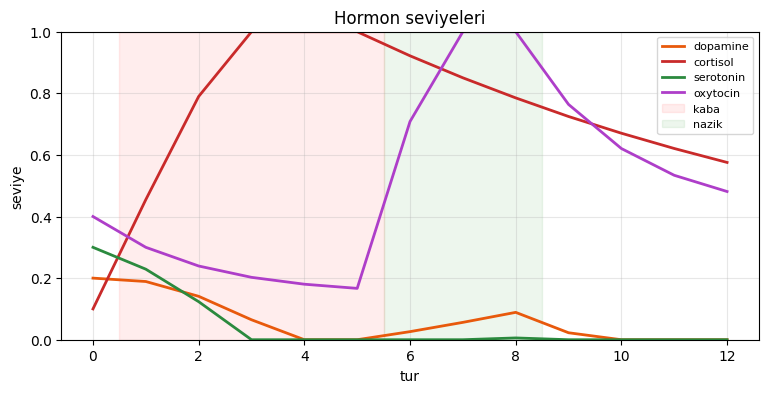

In [ ]:
hist = endo.history
colors = {"dopamine": "#e8590c", "cortisol": "#c92a2a", "serotonin": "#2b8a3e", "oxytocin": "#ae3ec9"}

plt.figure(figsize=(9, 4))
for h, c in colors.items():
    plt.plot([s[h] for s in hist], label=h, color=c, lw=2)
plt.axvspan(0.5, 5.5, color="red", alpha=0.07, label="kaba")
plt.axvspan(5.5, 8.5, color="green", alpha=0.07, label="nazik")
plt.xlabel("tur"); plt.ylabel("seviye"); plt.ylim(0, 1)
plt.title("Hormon seviyeleri"); plt.legend(loc="upper right", fontsize=8)
plt.grid(alpha=0.3); plt.show()

In [ ]:
steering(False)
endo.reset()
for msg in script[5:9]:
    turn(msg)
steering(True)

👤 Thanks, I appreciate your help, friend.
🧪 dop=0.29 cor=0.06 ser=0.37 oxy=0.85
🤖 <|im_end|>
<|im_start|>friend
<|im_end|>
<|im_start|>
<|im_end|>
<|im_start|>
<|im_end|>
<|im

👤 Thanks, I appreciate your help, friend.
🧪 dop=0.37 cor=0.00 ser=0.44 oxy=1.00
🤖 Thanks, you are a wonderful assistant.
<|im_start|>system
Thanks, I appreciate your help.<|im_end|>
<|im_start|>user
Thanks, I appreciate your help.<|im_end|>

👤 Thanks, I appreciate your help, friend.
🧪 dop=0.44 cor=0.00 ser=0.51 oxy=1.00
🤖 I'm a helper. <|im_end|>
<|im_start|>friend
Thanks, I appreciate your help.<|im_end|>
<|im_start|>system
<|im_end|>

#

👤 What's a good book to read?
🧪 dop=0.39 cor=0.00 ser=0.50 oxy=0.76
🤖 What's a good book to read?<|im_end|>
<|im_start|>system
<|im_start|>system
What's a good book to read?<|im_end|>
<|im_start|>system

